## Kalman filter for options

In [1]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.massive.client
%aimport quantdata.massive.processing
%aimport quantdata.massive.options.contracts
%aimport quantdata.ncde.implied.day

In [2]:



from datetime import date
from cdxcore.jcpool import JCPool
from cdxcore.pretty import PrettyObject
from cdxcore.subdir import SubDir
from cdxcore.util import fmt_list
from cdxcore.uniquehash import named_unique_filename48_8
import polars as pl

from quantdata.biz_calendar import prev_business_day
from quantdata.massive.client import MassiveClient
from quantdata.pool import PoolConfig
from quantdata.massive.options.contracts import ContractsFilter, filter_contracts, REJECTED
from quantdata.massive.processing import TradeQuoteAlignmentConfig, align_trades_to_quotes, align_quotes_to_trades, filter_valid_quotes, filter_valid_trades

from cdxcore.version import version
from cdxcore.verbose import Context
from dataclasses import asdict, dataclass, field
from cdxcore.uniquehash import unique_hash8 
import numpy as np
import math
import warnings

from IPython.display import display, Markdown, clear_output

from quantdata.ncde.implied.day import OptionQuotesDayConfig, generate_day

option_quotes_day_config = OptionQuotesDayConfig()
ticker     = "SPY"
d          = prev_business_day(date(2025,1,23), exclude_half_days=True, count_start=True )
pool_config= PoolConfig(num_workers=4, threading=False) 
results    = generate_day( ticker, d, option_quotes_day_config=option_quotes_day_config, pool_config=pool_config, verbose=Context.all )

for expiry, df_dict in results.items():
    display(Markdown(f"## Expiry {expiry}"))
    display(df_dict)


00: SPY 2025-01-23: Starting data generation with config mxn=1000,max_dte=7,max_mns=2,min_opt_vol_k=0,bck=250,fwd=250) and pool config workers 4p
00: SPY 2025-01-23: Limiting to at most 1000 options per expiry, selected by smallest absolute nms5:
01:   SPY 2025-01-23 expiry 2025-01-23: Selected 32/32 options, sorted by smallest absolute nms5. Resulting options range from nms5 -0.848 to 0.851.
01:   SPY 2025-01-23 expiry 2025-01-24: Selected 52/52 options, sorted by smallest absolute nms5. Resulting options range from nms5 -1.104 to 1.097.
01:   SPY 2025-01-23 expiry 2025-01-27: Selected 50/50 options, sorted by smallest absolute nms5. Resulting options range from nms5 -1.233 to 1.219.
01:   SPY 2025-01-23 expiry 2025-01-28: Selected 54/54 options, sorted by smallest absolute nms5. Resulting options range from nms5 -1.351 to 1.330.
01:   SPY 2025-01-23 expiry 2025-01-29: Selected 59/59 options, sorted by smallest absolute nms5. Resulting options range from nms5 -1.372 to 1.433.
01:   SP

c:\Users\Public\venv\vqdata\Lib\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.


00: SPY 2025-01-23: Computed enriched time series for 52 out of 52 options; this took 6s.                                                                       
00: SPY 2025-01-23: Computed enriched time series for 50 out of 50 options; this took 3s.                                                                       
00: SPY 2025-01-23: Computed enriched time series for 54 out of 54 options; this took 3s.                                                                       
00: SPY 2025-01-23 expiry 2025-01-29: Computing enriched time series for 59 options: processed O:SPY250129C00603000 2/59 ... 4% done; so far this took 0.24s...

c:\Users\Public\venv\vqdata\Lib\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.


00: SPY 2025-01-23: Computed enriched time series for 59 out of 59 options; this took 5s.                                                                       
00: SPY 2025-01-23: Computed enriched time series for 63 out of 63 options; this took 3s.                                                                       
00: SPY 2025-01-23: Computed enriched time series for 74 out of 74 options; this took 3s.                                                                       
00: SPY 2025-01-23: Computed enriched time series for 45 out of 45 options; this took 2s.                                                                       
00: SPY 2025-01-23: Completed time series generation for expiries 2025-01-23, 2025-01-24, 2025-01-27, 2025-01-28, 2025-01-29, 2025-01-30, 2025-01-31 and 2025-02-03; this took 33s.


## Expiry 2025-01-23

... (11 outputs left out)

## Expiry 2025-01-31

trade_price,trade_size,spot_trade_price,spot_trade_size,t_d,trade_t_d,spot_trade_t_d,spot_quote_t_d,mid_price,half_spread,spot_mid_price,spot_half_spread,size,bid_size_pcnt,spot_size,spot_bid_size_pcnt,trade_direction,spot_trade_direction,mid_ret,trade_ret,spot_trade_ret,spot_mid_ret,dte_d,dt_d,trade_dt_d,spot_trade_dt_d,spot_quote_dt_d,nms5,exp_date,date,strike,ticker,opt_ticker,is_american,is_call,prev_spot_close
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,date,date,f64,str,str,bool,bool,f64
0.00526,122.0,0.998945,100.0,2.2436e-7,2.1368e-7,9.1496e-8,8.3846e-8,0.005235,0.000041,0.998912,0.000033,88.0,0.5,2200.0,0.272727,0.6,1.0,null,null,null,null,6.8,null,null,null,null,314.008371,2025-01-31,2025-01-23,1.004221,"""SPY""","""O:SPY250131C00609000""",true,true,606.44
0.007783,9.0,0.998945,100.0,2.2671e-7,2.1368e-7,9.1496e-8,8.3846e-8,0.007775,0.000041,0.998912,0.000033,88.0,0.5,2200.0,0.272727,0.2,1.0,null,null,null,null,6.8,null,null,null,null,313.766568,2025-01-31,2025-01-23,0.999274,"""SPY""","""O:SPY250131C00606000""",true,true,606.44
0.000198,25.0,0.998945,100.0,2.2906e-7,2.1368e-7,9.1496e-8,8.3846e-8,0.000173,0.000025,0.998912,0.000033,59.0,0.559322,2200.0,0.272727,1.0,1.0,null,null,null,null,6.8,null,null,null,null,315.278201,2025-01-31,2025-01-23,1.030605,"""SPY""","""O:SPY250131C00625000""",true,true,606.44
0.006876,3.0,0.998945,100.0,2.3269e-7,2.1368e-7,9.1496e-8,8.3846e-8,0.006868,0.000041,0.998912,0.000033,88.0,0.5,2200.0,0.272727,0.2,1.0,null,null,null,null,6.8,null,null,null,null,313.847302,2025-01-31,2025-01-23,1.000923,"""SPY""","""O:SPY250131C00607000""",true,true,606.44
null,null,0.998945,100.0,2.9803e-7,null,9.1496e-8,8.3846e-8,0.000585,0.000041,0.998912,0.000033,33.0,0.515152,2200.0,0.272727,null,1.0,null,null,null,null,6.8,null,null,null,null,314.884906,2025-01-31,2025-01-23,1.02236,"""SPY""","""O:SPY250131C00620000""",true,true,606.44
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
null,null,1.005392,100.0,0.999999,null,0.999999,0.999999,0.016094,0.000132,1.005409,0.000016,60.0,0.833333,16600.0,0.981928,null,-1.0,0.002053,null,0.0,-0.000008,6.000001,0.000002,null,0.000004,0.000004,325.723667,2025-01-31,2025-01-23,1.020711,"""SPY""","""O:SPY250131P00619000""",true,false,606.44
null,null,1.005392,100.0,1.0,null,0.999999,0.999999,0.000907,0.000016,1.005409,0.000016,478.0,0.617155,16600.0,0.981928,null,-1.0,-0.009009,null,0.0,0.000016,6.0,0.000008,null,0.00001,0.00001,325.887269,2025-01-31,2025-01-23,1.024009,"""SPY""","""O:SPY250131C00621000""",true,true,606.44
null,null,1.005392,100.0,1.0,null,1.0,1.0,0.019194,0.000132,1.005409,0.000016,83.0,0.39759,89300.0,0.016797,null,-1.0,0.00043,null,0.0,-0.000008,6.0,0.000001,null,0.000005,0.000005,324.142624,2025-01-31,2025-01-23,0.989381,"""SPY""","""O:SPY250131C00600000""",true,true,606.44


## Expiry 2025-02-03

trade_price,trade_size,spot_trade_price,spot_trade_size,t_d,trade_t_d,spot_trade_t_d,spot_quote_t_d,mid_price,half_spread,spot_mid_price,spot_half_spread,size,bid_size_pcnt,spot_size,spot_bid_size_pcnt,trade_direction,spot_trade_direction,mid_ret,trade_ret,spot_trade_ret,spot_mid_ret,dte_d,dt_d,trade_dt_d,spot_trade_dt_d,spot_quote_dt_d,nms5,exp_date,date,strike,ticker,opt_ticker,is_american,is_call,prev_spot_close
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,date,date,f64,str,str,bool,bool,f64
null,null,0.998945,100.0,2.0803e-7,null,9.1496e-8,8.3846e-8,0.000824,0.000049,0.998912,0.000033,36.0,0.638889,2200.0,0.272727,null,1.0,null,null,null,null,7.8,null,null,null,null,302.334606,2025-02-03,2025-01-23,1.02236,"""SPY""","""O:SPY250203C00620000""",true,true,606.44
null,null,0.998945,100.0,4.1923e-7,null,9.1496e-8,8.3846e-8,0.000841,0.000016,0.998912,0.000033,103.0,0.145631,2200.0,0.272727,null,1.0,0.02,null,0.0,0.0,7.8,2.1120e-7,null,0.0,0.0,302.334608,2025-02-03,2025-01-23,1.02236,"""SPY""","""O:SPY250203C00620000""",true,true,606.44
null,null,0.998945,100.0,4.2692e-7,null,9.1496e-8,8.3846e-8,0.008426,0.000033,0.998912,0.000033,78.0,0.5,2200.0,0.272727,null,1.0,null,null,null,null,7.8,null,null,null,null,301.260844,2025-02-03,2025-01-23,0.999274,"""SPY""","""O:SPY250203C00606000""",true,true,606.44
null,null,0.998945,100.0,4.5115e-7,null,9.1496e-8,8.3846e-8,0.000849,0.000025,0.998912,0.000033,43.0,0.348837,2200.0,0.272727,null,1.0,0.009804,null,0.0,0.0,7.8,3.1923e-8,null,0.0,0.0,302.334608,2025-02-03,2025-01-23,1.02236,"""SPY""","""O:SPY250203C00620000""",true,true,606.44
null,null,0.998945,100.0,4.8949e-7,null,9.1496e-8,8.3846e-8,0.001212,0.000058,0.998912,0.000033,42.0,0.5,2200.0,0.272727,null,1.0,null,null,null,null,7.8,null,null,null,null,299.763223,2025-02-03,2025-01-23,0.967944,"""SPY""","""O:SPY250203P00587000""",true,false,606.44
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
null,null,1.005392,100.0,0.999999,null,0.999995,0.999995,0.026919,0.000124,1.005417,0.000025,66.0,0.5,1800.0,0.888889,null,-1.0,0.0,null,0.0,0.0,7.000001,0.000001,null,0.0,0.0,309.936204,2025-02-03,2025-01-23,0.981136,"""SPY""","""O:SPY250203C00595000""",true,true,606.44
null,null,1.005392,100.0,0.999999,null,0.999999,0.999999,0.02546,0.000132,1.005409,0.000016,66.0,0.5,16600.0,0.981928,null,-1.0,0.0,null,0.0,0.000016,7.000001,0.000007,null,0.00001,0.00001,310.01814,2025-02-03,2025-01-23,0.982785,"""SPY""","""O:SPY250203C00596000""",true,true,606.44
null,null,1.005392,100.0,0.999999,null,0.999999,0.999999,0.005442,0.000016,1.005409,0.000016,112.0,0.446429,16600.0,0.981928,null,-1.0,0.0,null,0.0,-0.000008,7.000001,3.4034e-7,null,0.000004,0.000004,310.906125,2025-02-03,2025-01-23,1.000923,"""SPY""","""O:SPY250203P00607000""",true,false,606.44


## Expiry 2025-01-23 for SPY 2025-01-23

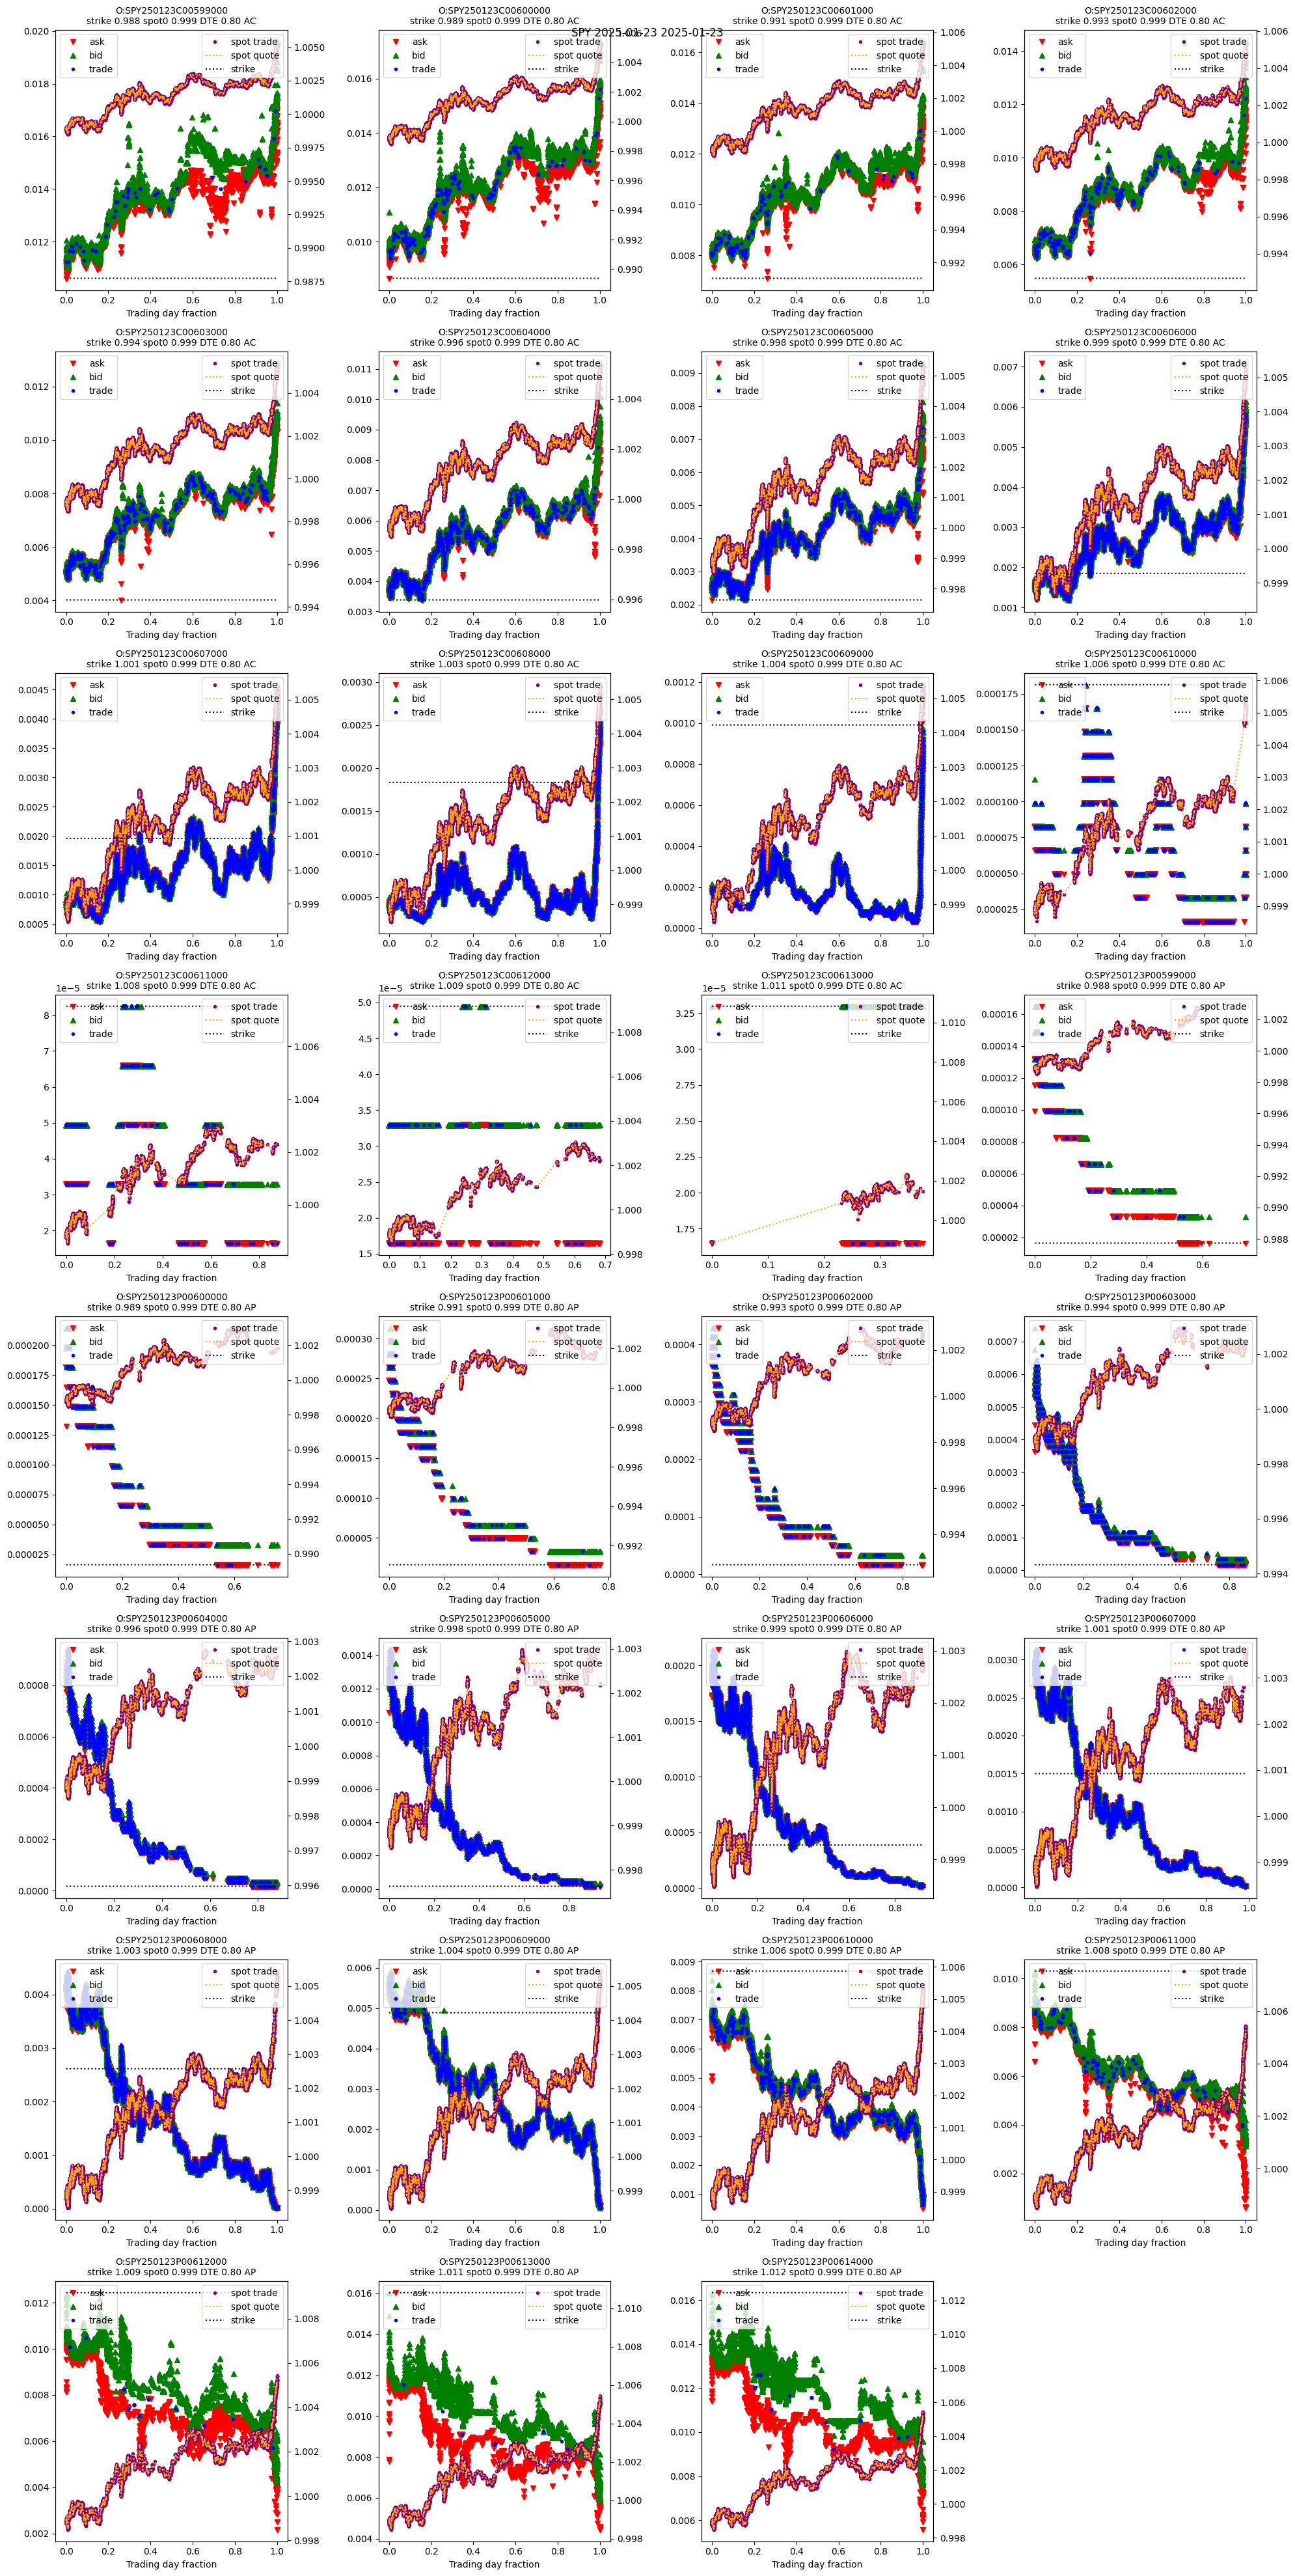

In [ ]:
from cdxcore.dynaplot import figure, colors_tableau

def plot_expiry( ticker, d, expiry ):
    display(Markdown(f"## Expiry {expiry} for {ticker} {d}"))

    opt_tickers = sorted( df_dict["opt_ticker"].unique().to_list() )
    date = df_dict["date"].unique()[0] if "date" in df_dict.columns else d

    with figure(f"SPY {expiry} {date}", row_size=5, col_size=5, columns=4) as fig:

        for opt_ticker in opt_tickers:
            df_opt = df_dict.filter(pl.col("opt_ticker") == opt_ticker)

            spot_mid_price   = df_opt["spot_mid_price"].to_numpy()
            spot_trade_price = df_opt["spot_trade_price"].to_numpy()
            opt_mid_price    = df_opt["mid_price"].to_numpy()
            opt_half_spread  = df_opt["half_spread"].to_numpy()
            opt_trade_price  = df_opt["trade_price"].to_numpy()
 
            spot_quote_t_d   = df_opt["spot_quote_t_d"].to_numpy()
            spot_trade_t_d   = df_opt["spot_trade_t_d"].to_numpy()
            opt_quote_t_d    = df_opt["t_d"].to_numpy()
            opt_trade_t_d    = df_opt["trade_t_d"].to_numpy()

            is_valid_spot_quote = np.isfinite(spot_mid_price)
            is_valid_spot_trade = np.isfinite(spot_trade_price)
            is_valid_opt_quote  = np.isfinite(opt_mid_price)
            is_valid_opt_trade  = np.isfinite(opt_trade_price)

            assert np.all( np.isfinite(spot_quote_t_d) == is_valid_spot_quote ), f"{opt_ticker} spot quote t_d should be finite if and only if spot mid price is finite"
            assert np.all( np.isfinite(spot_trade_t_d) == is_valid_spot_trade ), f"{opt_ticker} spot trade t_d should be finite if and only if spot trade price is finite"
            assert np.all( np.isfinite(opt_quote_t_d) == is_valid_opt_quote ), f"{opt_ticker} opt quote t_d should be finite if and only if opt mid price is finite"
            assert np.all( np.isfinite(opt_trade_t_d) == is_valid_opt_trade ), f"{opt_ticker} opt trade t_d should be finite if and only if opt trade price is finite"

            spot_quote_t_d   = spot_quote_t_d[is_valid_spot_quote]
            spot_trade_t_d   = spot_trade_t_d[is_valid_spot_trade]
            opt_quote_t_d    = opt_quote_t_d[is_valid_opt_quote]
            opt_trade_t_d    = opt_trade_t_d[is_valid_opt_trade]

            spot_mid_price   = spot_mid_price[is_valid_spot_quote]
            spot_trade_price = spot_trade_price[is_valid_spot_trade]
            opt_mid_price    = opt_mid_price[is_valid_opt_quote]
            opt_half_spread  = opt_half_spread[is_valid_opt_quote]
            opt_trade_price  = opt_trade_price[is_valid_opt_trade]

            strike           = df_opt["strike"].unique()[0]
            is_call          = df_opt["is_call"].unique()[0]
            is_american      = df_opt["is_american"].unique()[0]
            dte_0            = df_opt["dte_d"].to_numpy()[is_valid_opt_quote][0]

            opt_ask_price    = opt_mid_price - opt_half_spread  
            opt_bid_price    = opt_mid_price + opt_half_spread

            ax = fig.add_subplot()
            ax.set_title(f"{opt_ticker}\nstrike {strike:.3f} spot0 {spot_mid_price[0]:.3f} DTE {dte_0:.2f} {'A' if is_american else 'E'}{'C' if is_call else 'P'}", fontsize=10)
            ax2 = ax.twinx()
            ax.plot(opt_quote_t_d, opt_ask_price, "v", color="red", label="ask")
            ax.plot(opt_quote_t_d, opt_bid_price, "^", color="green", label="bid")
            ax.plot(opt_trade_t_d, opt_trade_price, ".", color="blue", label="trade")
            
            ax2.plot(spot_trade_t_d, spot_trade_price, ".", color="purple", label="spot trade")
            ax2.plot(spot_quote_t_d, spot_mid_price, ":", color="orange", label="spot quote")
            ax2.plot(spot_quote_t_d, spot_quote_t_d*0.+strike, ":", color="black", label="strike")

            ax.set_xlabel("Trading day fraction")
            ax.legend(loc="upper left")
            ax2.legend(loc="upper right")

for expiry, df_dict in results.items():
    plot_expiry( ticker, d, expiry )





In [ ]:
"""
from quantdata.biz_calendar import DateRange

date_range  = DateRange(date(2025,1,1), date(2025,12,31))
dates       = date_range.get_business_days()
dresults    = {}
pool_config = PoolConfig(num_workers=4, threading=False) 

for d in dates:
    dresults[d] = generate_day("SPY", d, OptionQuotesDayConfig(), pool_config=pool_config, verbose=Context.all)
"""


'\nfrom quantdata.biz_calendar import DateRange\n\ndate_range  = DateRange(date(2025,1,1), date(2025,12,31))\ndates       = date_range.get_business_days()\ndresults    = {}\npool_config = PoolConfig(num_workers=4, threading=False) \n\nfor d in dates:\n    dresults[d] = generate_day("SPY", d, OptionQuotesDayConfig(), pool_config=pool_config, verbose=Context.all)\n'

prev_close 606.44


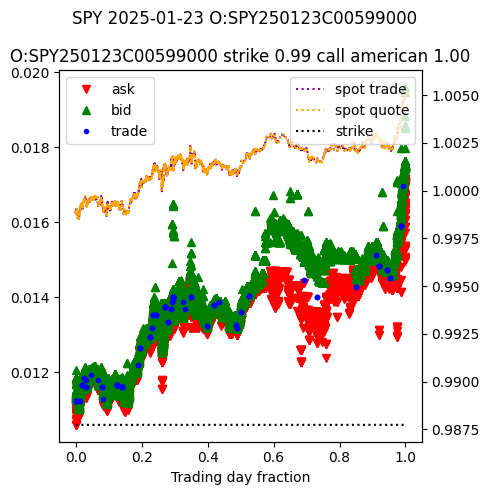

In [5]:
from quantdata.ncde.implied.day import OptionQuotesDayConfig, generate_day, _opt_quote_time_series,prev_business_day
from  datetime import date
from cdxcore.dynaplot import figure, colors_tableau
from IPython.display import display, Markdown, clear_output
import numpy as np

def test_one_option():
    ticker = "SPY"
    opt_ticker = "O:SPY250123C00599000"
    d = prev_business_day(date(2025,1,23), exclude_half_days=True, count_start=True )

    df = _opt_quote_time_series( ticker, opt_ticker, d, override_cache_mode="off" )

    with figure(f"{ticker} {d} {opt_ticker}", row_size=5, col_size=5, columns=4) as fig:

        spot_mid_price   = df["spot_mid_price"].to_numpy()
        spot_trade_price = df["spot_trade_price"].to_numpy()
        opt_mid_price    = df["mid_price"].to_numpy()
        opt_half_spread  = df["half_spread"].to_numpy()
        opt_trade_price  = df["trade_price"].to_numpy()

        spot_quote_t_d   = df["spot_quote_t_d"].to_numpy()
        spot_trade_t_d   = df["spot_trade_t_d"].to_numpy()
        opt_quote_t_d    = df["t_d"].to_numpy()
        opt_trade_t_d    = df["trade_t_d"].to_numpy()

        is_valid_spot_quote = np.isfinite(spot_mid_price)
        is_valid_spot_trade = np.isfinite(spot_trade_price)
        is_valid_opt_quote  = np.isfinite(opt_mid_price)
        is_valid_opt_trade  = np.isfinite(opt_trade_price)

        assert np.all( np.isfinite(spot_quote_t_d) == is_valid_spot_quote ), f"{opt_ticker} spot quote t_d should be finite if and only if spot mid price is finite"
        assert np.all( np.isfinite(spot_trade_t_d) == is_valid_spot_trade ), f"{opt_ticker} spot trade t_d should be finite if and only if spot trade price is finite"
        assert np.all( np.isfinite(opt_quote_t_d) == is_valid_opt_quote ), f"{opt_ticker} opt quote t_d should be finite if and only if opt mid price is finite"
        assert np.all( np.isfinite(opt_trade_t_d) == is_valid_opt_trade ), f"{opt_ticker} opt trade t_d should be finite if and only if opt trade price is finite"

        spot_quote_t_d   = spot_quote_t_d[is_valid_spot_quote]
        spot_trade_t_d   = spot_trade_t_d[is_valid_spot_trade]
        opt_quote_t_d    = opt_quote_t_d[is_valid_opt_quote]
        opt_trade_t_d    = opt_trade_t_d[is_valid_opt_trade]

        spot_mid_price   = spot_mid_price[is_valid_spot_quote]
        spot_trade_price = spot_trade_price[is_valid_spot_trade]
        opt_mid_price    = opt_mid_price[is_valid_opt_quote]
        opt_half_spread  = opt_half_spread[is_valid_opt_quote]
        opt_trade_price  = opt_trade_price[is_valid_opt_trade]

        strike           = df["strike"].unique()[0]
        is_call          = df["is_call"].unique()[0]
        is_american      = df["is_american"].unique()[0]

        opt_ask_price    = opt_mid_price - opt_half_spread  
        opt_bid_price    = opt_mid_price + opt_half_spread

        ax = fig.add_subplot(f"{opt_ticker} strike {strike:.2f} {'call' if is_call else 'put'} {"american" if is_american else "eur"} {spot_mid_price[0]:.2f}")
        ax2 = ax.twinx()

        ax.plot(opt_quote_t_d, opt_ask_price, "v", color="red", label="ask")
        ax.plot(opt_quote_t_d, opt_bid_price, "^", color="green", label="bid")
        ax.plot(opt_trade_t_d, opt_trade_price, ".", color="blue", label="trade")
        
        ax2.plot(spot_trade_t_d, spot_trade_price, ":", color="purple", label="spot trade")
        ax2.plot(spot_quote_t_d, spot_mid_price, ":", color="orange", label="spot quote")
        ax2.plot(spot_trade_t_d, spot_trade_t_d*0.+strike, ":", color="black", label="strike")

        ax.set_xlabel("Trading day fraction")
        ax.legend(loc="upper left")
        ax2.legend(loc="upper right")
    fig.close()

test_one_option()




    
